Install and imports

In [1]:
!pip install lightly --quiet

import os, json, time, math, random
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from torchvision.models import resnet50
from PIL import Image
import matplotlib.pyplot as plt

from lightly.loss import NTXentLoss
from lightly.models.modules import SimCLRProjectionHead
from lightly.transforms.simclr_transform import SimCLRTransform

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 891.2/891.2 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.6/165.6 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.8/155.8 kB 9.9 MB/s eta 0:00:00
Device: cuda


Load Part A split

In [2]:
SPLIT_PATH = "/kaggle/input/notebooks/yeamins/438-assignment-a/split.json"
DATA_ROOT  = "/kaggle/input/datasets/yeamins/ar-plaqsegm1-ultrasound-segmentation/Ar-PlaqSegm1 First Argentine database of B-mode ul"

with open(SPLIT_PATH) as f:
    split = json.load(f)

def fix_paths(records, new_root):
    fixed = []
    for rec in records:
        r = rec.copy()
        for key in ["img_path", "mask_path"]:
            parts = r[key].replace("\\", "/").split("/")
            r[key] = os.path.join(new_root, parts[-2], parts[-1])
        fixed.append(r)
    return fixed

train_records = fix_paths(split["train"], DATA_ROOT)   # unlabeled pretraining
val_records   = fix_paths(split["val"],   DATA_ROOT)   # labeled fine-tuning
test_records  = fix_paths(split["test"],  DATA_ROOT)   # monitoring + final eval
MASK_THRESHOLD = split["mask_threshold"]

print(f"Train (unlabeled): {len(train_records)}")
print(f"Val (labeled):     {len(val_records)}")
print(f"Test (eval):       {len(test_records)}")

Train (unlabeled): 416
Val (labeled):     73
Test (eval):       48


SimCLR dataset

In [3]:
class SimCLRPretrainDataset(Dataset):
    def __init__(self, records, transform):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        img = cv2.imread(self.records[idx]["img_path"], cv2.IMREAD_GRAYSCALE)
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)   # 3-channel for ResNet
        img = Image.fromarray(img)
        view1, view2 = self.transform(img)            # returns (view1, view2)
        return view1, view2

simclr_transform = SimCLRTransform(
    input_size=224,
    cj_prob=0.5,          # color jitter probability
    cj_strength=0.3,      # weaker jitter — grayscale doesn't need much
    gaussian_blur=0.5,
    random_gray_scale=0.0 # already grayscale
)

pretrain_ds = SimCLRPretrainDataset(train_records, simclr_transform)
pretrain_loader = DataLoader(
    pretrain_ds, batch_size=64, shuffle=True,
    num_workers=2, drop_last=True, pin_memory=True
)

print(f"Pretrain batches per epoch: {len(pretrain_loader)}")

Pretrain batches per epoch: 6


Sanity check: visualize two views of same image

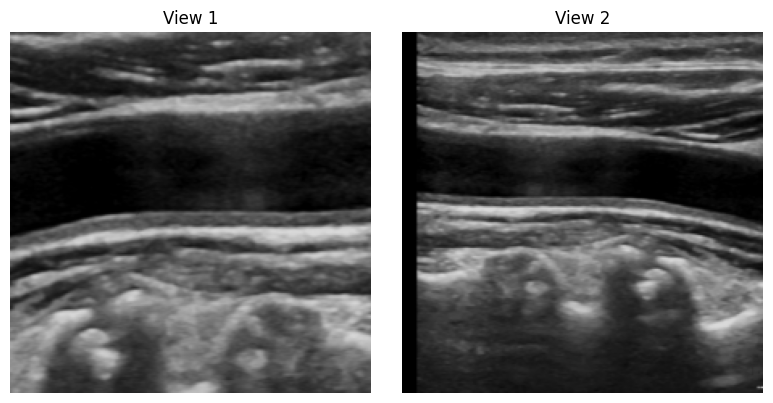

In [4]:
sample_v1, sample_v2 = pretrain_ds[0]
def denorm(t):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    return (t * std + mean).clamp(0,1).permute(1,2,0).numpy()

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(denorm(sample_v1)); ax[0].set_title("View 1"); ax[0].axis("off")
ax[1].imshow(denorm(sample_v2)); ax[1].set_title("View 2"); ax[1].axis("off")
plt.tight_layout(); plt.show()

SimCLR model (ResNet-50 encoder + projection head)

In [5]:
class SimCLRModel(nn.Module):
    def __init__(self):
        super().__init__()
        backbone = resnet50(weights="IMAGENET1K_V2")
        self.encoder = nn.Sequential(*list(backbone.children())[:-1])  # drop FC
        self.projection = SimCLRProjectionHead(
            input_dim=2048, hidden_dim=2048, output_dim=128
        )

    def forward(self, x):
        h = self.encoder(x).flatten(1)   # [B, 2048]
        z = self.projection(h)           # [B, 128]
        return z

model = SimCLRModel().to(device)
print(f"Params: {sum(p.numel() for p in model.parameters())/1e6:.1f}M")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 199MB/s]


Params: 28.0M


Pretraining loop

In [6]:
PRETRAIN_CONFIG = {
    "epochs": 50,
    "batch_size": 64,
    "lr": 3e-4,
    "weight_decay": 1e-6,
    "temperature": 0.5,        # NT-Xent τ — report at viva
    "optimizer": "AdamW",
    "warmup_epochs": 5,
}

criterion = NTXentLoss(temperature=PRETRAIN_CONFIG["temperature"])
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=PRETRAIN_CONFIG["lr"],
    weight_decay=PRETRAIN_CONFIG["weight_decay"]
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=PRETRAIN_CONFIG["epochs"]
)

pretrain_losses = []
epoch_times = []
model.train()

for epoch in range(PRETRAIN_CONFIG["epochs"]):
    t0 = time.time()
    epoch_loss = 0.0

    for view1, view2 in pretrain_loader:
        view1, view2 = view1.to(device), view2.to(device)
        z1 = model(view1)
        z2 = model(view2)
        loss = criterion(z1, z2)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    scheduler.step()
    avg_loss = epoch_loss / len(pretrain_loader)
    dt = time.time() - t0
    pretrain_losses.append(avg_loss)
    epoch_times.append(dt)
    print(f"Epoch {epoch+1:02d}/50 | NT-Xent loss: {avg_loss:.4f} | {dt:.1f}s")

# Save encoder only (drop projection head)
torch.save(model.encoder.state_dict(), "/kaggle/working/simclr_encoder.pt")
print(f"\nMean epoch time: {np.mean(epoch_times):.1f}s")
print(f"Total pretrain time: {sum(epoch_times)/60:.1f} min")

Epoch 01/50 | NT-Xent loss: 4.6370 | 11.0s
Epoch 02/50 | NT-Xent loss: 4.3977 | 8.2s
Epoch 03/50 | NT-Xent loss: 4.2427 | 8.2s
Epoch 04/50 | NT-Xent loss: 4.0642 | 8.2s
Epoch 05/50 | NT-Xent loss: 4.0069 | 8.3s
Epoch 06/50 | NT-Xent loss: 3.8915 | 8.4s
Epoch 07/50 | NT-Xent loss: 3.8674 | 8.5s
Epoch 08/50 | NT-Xent loss: 3.7671 | 8.5s
Epoch 09/50 | NT-Xent loss: 3.7552 | 8.6s
Epoch 10/50 | NT-Xent loss: 3.6964 | 8.7s
Epoch 11/50 | NT-Xent loss: 3.6452 | 8.6s
Epoch 12/50 | NT-Xent loss: 3.6159 | 8.7s
Epoch 13/50 | NT-Xent loss: 3.5675 | 9.1s
Epoch 14/50 | NT-Xent loss: 3.5347 | 9.0s
Epoch 15/50 | NT-Xent loss: 3.5868 | 9.0s
Epoch 16/50 | NT-Xent loss: 3.5678 | 9.2s
Epoch 17/50 | NT-Xent loss: 3.5241 | 9.3s
Epoch 18/50 | NT-Xent loss: 3.5484 | 9.3s
Epoch 19/50 | NT-Xent loss: 3.5223 | 9.1s
Epoch 20/50 | NT-Xent loss: 3.5006 | 9.0s
Epoch 21/50 | NT-Xent loss: 3.4860 | 9.0s
Epoch 22/50 | NT-Xent loss: 3.4607 | 9.1s
Epoch 23/50 | NT-Xent loss: 3.4977 | 9.0s
Epoch 24/50 | NT-Xent loss: 3.472

Plot pretraining loss

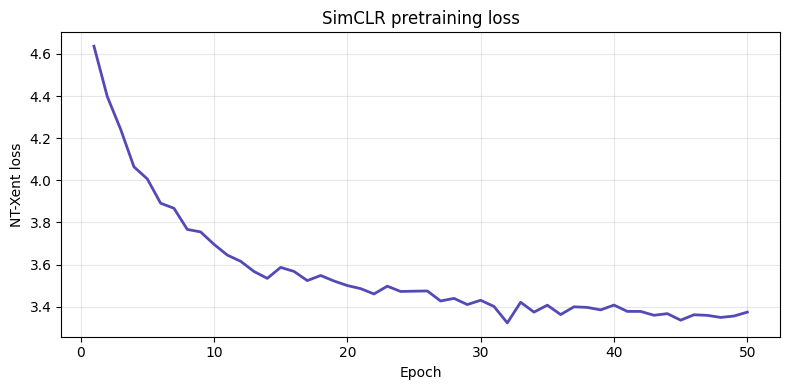

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, 51), pretrain_losses, color="#534AB7", linewidth=2)
ax.set_xlabel("Epoch"); ax.set_ylabel("NT-Xent loss")
ax.set_title("SimCLR pretraining loss")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/simclr_pretrain_loss.png", dpi=150)
plt.show()

Segmentation model (encoder + decoder)

In [8]:
class ResNetEncoder(nn.Module):
    """Returns multi-scale features from ResNet-50."""
    def __init__(self, pretrained_path):
        super().__init__()
        backbone = resnet50(weights=None)
        sd = torch.load(pretrained_path, map_location="cpu")
        # Load the SSL-pretrained weights (encoder was children[:-1])
        # Map keys back to backbone structure
        backbone_sd = {}
        keys = list(backbone.state_dict().keys())
        vals = list(sd.values())
        for k, v in zip(keys, vals):
            backbone_sd[k] = v
        backbone.load_state_dict(backbone_sd, strict=False)

        self.stem   = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool)
        self.layer1 = backbone.layer1   # C2:  256 ch, /4
        self.layer2 = backbone.layer2   # C3:  512 ch, /8
        self.layer3 = backbone.layer3   # C4: 1024 ch, /16
        self.layer4 = backbone.layer4   # C5: 2048 ch, /32

    def forward(self, x):
        x  = self.stem(x)
        c2 = self.layer1(x)
        c3 = self.layer2(c2)
        c4 = self.layer3(c3)
        c5 = self.layer4(c4)
        return c3, c4, c5

class MultiScaleDecoder(nn.Module):
    """FPN-style upsampling decoder producing per-pixel logits."""
    def __init__(self, num_classes=2):
        super().__init__()
        self.reduce5 = nn.Conv2d(2048, 256, 1)
        self.reduce4 = nn.Conv2d(1024, 256, 1)
        self.reduce3 = nn.Conv2d(512,  256, 1)

        self.fuse4 = nn.Conv2d(256, 256, 3, padding=1)
        self.fuse3 = nn.Conv2d(256, 256, 3, padding=1)

        self.head = nn.Sequential(
            nn.Conv2d(256, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, num_classes, 1),
        )

    def forward(self, c3, c4, c5, out_size):
        p5 = self.reduce5(c5)
        p4 = self.reduce4(c4) + F.interpolate(p5, size=c4.shape[-2:], mode="bilinear", align_corners=False)
        p4 = self.fuse4(p4)
        p3 = self.reduce3(c3) + F.interpolate(p4, size=c3.shape[-2:], mode="bilinear", align_corners=False)
        p3 = self.fuse3(p3)
        logits = self.head(p3)
        logits = F.interpolate(logits, size=out_size, mode="bilinear", align_corners=False)
        return logits

class SegModel(nn.Module):
    def __init__(self, encoder_path, num_classes=2):
        super().__init__()
        self.encoder = ResNetEncoder(encoder_path)
        self.decoder = MultiScaleDecoder(num_classes)

    def forward(self, x):
        H, W = x.shape[-2:]
        c3, c4, c5 = self.encoder(x)
        return self.decoder(c3, c4, c5, (H, W))

Fine-tuning dataset (val split with masks, test split for monitoring)

In [9]:
IMG_SIZE = 512

class SegDataset(Dataset):
    def __init__(self, records, augment=False):
        self.records = records
        self.augment = augment
        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
        self.std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        img = cv2.imread(rec["img_path"], cv2.IMREAD_GRAYSCALE)
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
        mask = cv2.imread(rec["mask_path"], cv2.IMREAD_GRAYSCALE)
        mask = (mask > MASK_THRESHOLD).astype(np.int64)

        img  = cv2.resize(img,  (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)

        if self.augment and random.random() < 0.5:
            img = np.fliplr(img).copy(); mask = np.fliplr(mask).copy()

        img_t = torch.from_numpy(img).permute(2,0,1).float() / 255.0
        img_t = (img_t - self.mean) / self.std
        mask_t = torch.from_numpy(mask).long()
        return img_t, mask_t, rec["idx"]

finetune_loader = DataLoader(
    SegDataset(val_records, augment=True),
    batch_size=8, shuffle=True, num_workers=2, pin_memory=True
)
test_loader = DataLoader(
    SegDataset(test_records, augment=False),
    batch_size=8, shuffle=False, num_workers=2, pin_memory=True
)
print(f"Fine-tune batches: {len(finetune_loader)} | Test batches: {len(test_loader)}")

Fine-tune batches: 10 | Test batches: 6


Metric functions

In [10]:
def dice_loss(logits, target, smooth=1.0):
    probs = F.softmax(logits, dim=1)
    target_1h = F.one_hot(target, num_classes=2).permute(0,3,1,2).float()
    intersect = (probs * target_1h).sum(dim=(2,3))
    union = probs.sum(dim=(2,3)) + target_1h.sum(dim=(2,3))
    return 1 - ((2 * intersect + smooth) / (union + smooth)).mean()

ce_loss = nn.CrossEntropyLoss()

def compute_metrics(pred, gt, num_classes=2):
    conf = np.zeros((num_classes, num_classes), dtype=np.int64)
    for g in range(num_classes):
        for p in range(num_classes):
            conf[g, p] = int(((gt == g) & (pred == p)).sum())

    iou_per_class, dice_per_class = [], []
    for c in range(num_classes):
        tp = conf[c, c]
        fn = conf[c, :].sum() - tp
        fp = conf[:, c].sum() - tp
        iou  = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else float("nan")
        dice = 2*tp / (2*tp + fp + fn) if (2*tp + fp + fn) > 0 else float("nan")
        iou_per_class.append(iou); dice_per_class.append(dice)

    overall_acc = float(np.diag(conf).sum() / conf.sum()) if conf.sum() > 0 else 0.0
    per_class_acc = [conf[c,c]/conf[c,:].sum() if conf[c,:].sum() > 0 else float("nan")
                     for c in range(num_classes)]
    return {
        "mIoU": float(np.nanmean(iou_per_class)),
        "iou_per_class": iou_per_class,
        "mean_dice": float(np.nanmean(dice_per_class)),
        "dice_per_class": dice_per_class,
        "overall_pixel_acc": overall_acc,
        "mean_pixel_acc": float(np.nanmean(per_class_acc)),
        "per_class_acc": per_class_acc,
        "confusion_matrix": conf.tolist(),
    }

def evaluate(model, loader):
    model.eval()
    conf_total = np.zeros((2, 2), dtype=np.int64)
    per_image = []
    with torch.no_grad():
        for imgs, masks, idxs in loader:
            imgs = imgs.to(device)
            logits = model(imgs)
            preds = logits.argmax(1).cpu().numpy()
            gts = masks.numpy()
            for i in range(len(preds)):
                m = compute_metrics(preds[i], gts[i])
                m["idx"] = idxs[i] if isinstance(idxs[i], str) else str(idxs[i].item())
                m["plaque_iou"] = m["iou_per_class"][1]
                m["has_plaque"] = int(gts[i].sum() > 0)
                per_image.append(m)
                conf_total += np.array(m["confusion_matrix"])
    overall = compute_metrics(np.zeros((1,1)), np.zeros((1,1)))  # placeholder
    overall = {"confusion_matrix": conf_total.tolist()}
    # Recompute overall from aggregated confusion matrix
    conf = conf_total
    iou = [conf[c,c] / max(conf[c,:].sum()+conf[:,c].sum()-conf[c,c], 1) for c in range(2)]
    dice = [2*conf[c,c] / max(2*conf[c,c] + (conf[c,:].sum()-conf[c,c]) + (conf[:,c].sum()-conf[c,c]), 1) for c in range(2)]
    overall.update({
        "mIoU": float(np.mean(iou)),
        "iou_per_class": iou,
        "mean_dice": float(np.mean(dice)),
        "dice_per_class": dice,
        "overall_pixel_acc": float(np.diag(conf).sum()/conf.sum()),
    })
    return overall, per_image

Fine-tuned training

In [11]:
FT_CONFIG = {
    "epochs": 50,
    "batch_size": 8,
    "encoder_lr": 1e-5,
    "decoder_lr": 1e-4,
    "weight_decay": 1e-4,
    "loss": "CE + Dice",
    "frozen_or_finetuned": "fine-tuned",
    "input_resolution": IMG_SIZE,
}

seg_model_ft = SegModel("/kaggle/working/simclr_encoder.pt", num_classes=2).to(device)

optimizer_ft = torch.optim.AdamW([
    {"params": seg_model_ft.encoder.parameters(), "lr": FT_CONFIG["encoder_lr"]},
    {"params": seg_model_ft.decoder.parameters(), "lr": FT_CONFIG["decoder_lr"]},
], weight_decay=FT_CONFIG["weight_decay"])

scheduler_ft = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_ft, T_max=FT_CONFIG["epochs"])

train_losses_ft, test_mious_ft, epoch_times_ft = [], [], []
best_miou_ft, best_state_ft, best_epoch_ft = 0.0, None, 0

for epoch in range(FT_CONFIG["epochs"]):
    t0 = time.time()
    seg_model_ft.train()
    epoch_loss = 0.0

    for imgs, masks, _ in finetune_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        logits = seg_model_ft(imgs)
        loss = ce_loss(logits, masks) + dice_loss(logits, masks)

        optimizer_ft.zero_grad()
        loss.backward()
        optimizer_ft.step()
        epoch_loss += loss.item()

    scheduler_ft.step()
    avg_loss = epoch_loss / len(finetune_loader)

    test_overall, _ = evaluate(seg_model_ft, test_loader)
    dt = time.time() - t0

    train_losses_ft.append(avg_loss)
    test_mious_ft.append(test_overall["mIoU"])
    epoch_times_ft.append(dt)

    if test_overall["mIoU"] > best_miou_ft:
        best_miou_ft = test_overall["mIoU"]
        best_state_ft = {k: v.cpu().clone() for k, v in seg_model_ft.state_dict().items()}
        best_epoch_ft = epoch + 1

    print(f"Epoch {epoch+1:02d}/50 [FT]     | loss={avg_loss:.4f} | test mIoU={test_overall['mIoU']:.4f} | {dt:.1f}s")

print(f"\n[Fine-tuned] Best test mIoU: {best_miou_ft:.4f} at epoch {best_epoch_ft}")
torch.save(best_state_ft, "/kaggle/working/simclr_seg_ft_best.pt")

Epoch 01/50 [FT]     | loss=1.2814 | test mIoU=0.3435 | 6.6s
Epoch 02/50 [FT]     | loss=0.9797 | test mIoU=0.4928 | 6.0s
Epoch 03/50 [FT]     | loss=0.8634 | test mIoU=0.5127 | 6.1s
Epoch 04/50 [FT]     | loss=0.8022 | test mIoU=0.6264 | 6.2s
Epoch 05/50 [FT]     | loss=0.7646 | test mIoU=0.6199 | 6.1s
Epoch 06/50 [FT]     | loss=0.7344 | test mIoU=0.6178 | 6.1s
Epoch 07/50 [FT]     | loss=0.7113 | test mIoU=0.6395 | 6.1s
Epoch 08/50 [FT]     | loss=0.7035 | test mIoU=0.6347 | 6.1s
Epoch 09/50 [FT]     | loss=0.6750 | test mIoU=0.6367 | 6.1s
Epoch 10/50 [FT]     | loss=0.6611 | test mIoU=0.6497 | 6.1s
Epoch 11/50 [FT]     | loss=0.6476 | test mIoU=0.6563 | 6.1s
Epoch 12/50 [FT]     | loss=0.6402 | test mIoU=0.6402 | 6.0s
Epoch 13/50 [FT]     | loss=0.6282 | test mIoU=0.6583 | 6.0s
Epoch 14/50 [FT]     | loss=0.6157 | test mIoU=0.6261 | 6.1s
Epoch 15/50 [FT]     | loss=0.5984 | test mIoU=0.6406 | 6.1s
Epoch 16/50 [FT]     | loss=0.5957 | test mIoU=0.6595 | 6.1s
Epoch 17/50 [FT]     | l

Fine-tuned curves

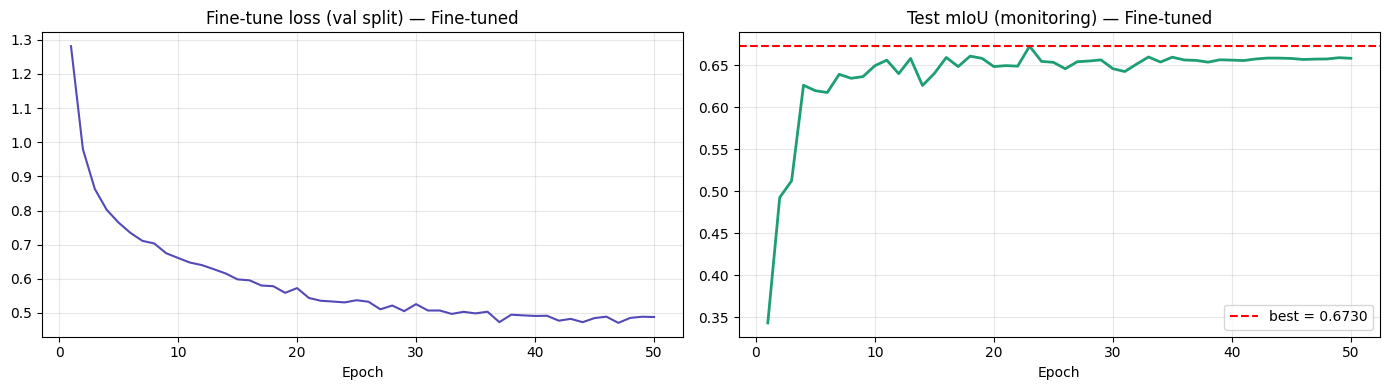

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(range(1, 51), train_losses_ft, color="#534AB7")
axes[0].set_title("Fine-tune loss (val split) — Fine-tuned"); axes[0].set_xlabel("Epoch"); axes[0].grid(alpha=0.3)

axes[1].plot(range(1, 51), test_mious_ft, color="#1D9E75", linewidth=2)
axes[1].axhline(best_miou_ft, color="red", linestyle="--", label=f"best = {best_miou_ft:.4f}")
axes[1].set_title("Test mIoU (monitoring) — Fine-tuned"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig("/kaggle/working/simclr_finetune_curves.png", dpi=150); plt.show()

Fine-tuned final evaluation

In [13]:
seg_model_ft.load_state_dict(torch.load("/kaggle/working/simclr_seg_ft_best.pt"))
final_overall_ft, final_per_image_ft = evaluate(seg_model_ft, test_loader)

print("=== SimCLR FINE-TUNED — test metrics ===")
print(f"Test mIoU:       {final_overall_ft['mIoU']:.4f}")
print(f"IoU background:  {final_overall_ft['iou_per_class'][0]:.4f}")
print(f"IoU plaque:      {final_overall_ft['iou_per_class'][1]:.4f}")
print(f"Mean Dice:       {final_overall_ft['mean_dice']:.4f}")
print(f"Dice plaque:     {final_overall_ft['dice_per_class'][1]:.4f}")
print(f"Pixel accuracy:  {final_overall_ft['overall_pixel_acc']:.4f}")

=== SimCLR FINE-TUNED — test metrics ===
Test mIoU:       0.6730
IoU background:  0.9923
IoU plaque:      0.3537
Mean Dice:       0.7593
Dice plaque:     0.5225
Pixel accuracy:  0.9923


Fine-tuned worst cases

Worst 10 by plaque IoU (fine-tuned):
    idx  plaque_iou  has_plaque
23  521    0.000000           1
25  523    0.000000           1
30  528    0.000000           1
40  538    0.069127           1
44  542    0.103524           1
45  543    0.206118           1
43  541    0.297611           1
35  533    0.297840           1
27  525    0.302256           1
26  524    0.326641           1


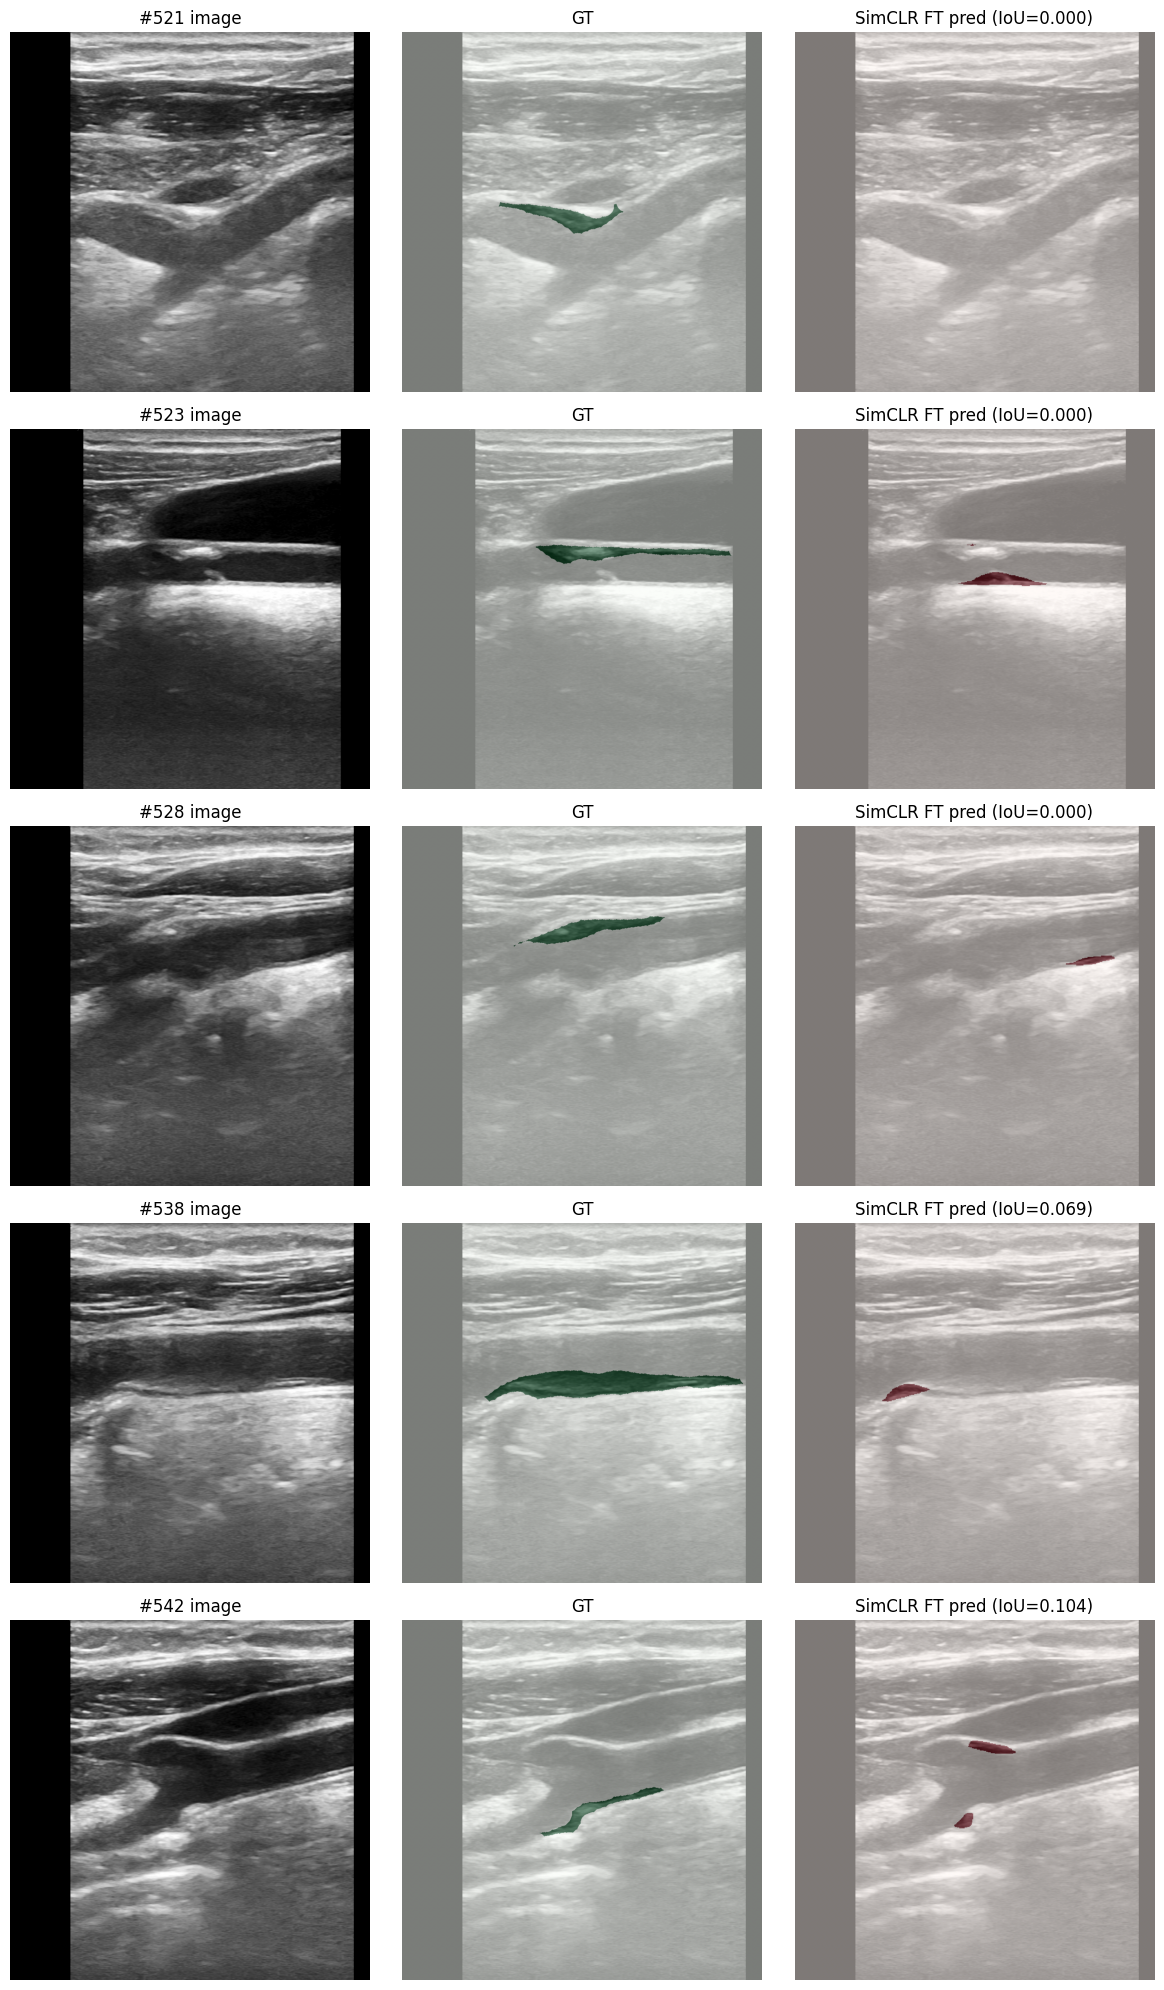

In [14]:
per_img_df_ft = pd.DataFrame([{
    "idx": r["idx"],
    "plaque_iou": r["plaque_iou"],
    "has_plaque": r["has_plaque"]
} for r in final_per_image_ft])

positive_ft = per_img_df_ft[per_img_df_ft["has_plaque"] == 1]
worst10_ft = positive_ft.nsmallest(10, "plaque_iou")
print("Worst 10 by plaque IoU (fine-tuned):"); print(worst10_ft)

per_img_df_ft.to_csv("/kaggle/working/simclr_per_image_ft.csv", index=False)

worst5_idx = worst10_ft["idx"].tolist()[:5]
fig, axes = plt.subplots(5, 3, figsize=(12, 20))
for row, idx in enumerate(worst5_idx):
    rec = next(r for r in test_records if str(r["idx"]) == str(idx))
    img = cv2.imread(rec["img_path"], cv2.IMREAD_GRAYSCALE)
    gt = (cv2.imread(rec["mask_path"], cv2.IMREAD_GRAYSCALE) > MASK_THRESHOLD).astype(np.uint8)

    img_t = torch.from_numpy(cv2.cvtColor(cv2.resize(img, (IMG_SIZE, IMG_SIZE)), cv2.COLOR_GRAY2RGB))
    img_t = (img_t.permute(2,0,1).float()/255.0 - torch.tensor([0.485,0.456,0.406]).view(3,1,1)) / torch.tensor([0.229,0.224,0.225]).view(3,1,1)
    seg_model_ft.eval()
    with torch.no_grad():
        pred = seg_model_ft(img_t.unsqueeze(0).to(device)).argmax(1)[0].cpu().numpy()
    pred = cv2.resize(pred.astype(np.uint8), (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)

    axes[row,0].imshow(img, cmap="gray"); axes[row,0].set_title(f"#{idx} image"); axes[row,0].axis("off")
    axes[row,1].imshow(img, cmap="gray"); axes[row,1].imshow(gt, cmap="Greens", alpha=0.5); axes[row,1].set_title("GT"); axes[row,1].axis("off")
    axes[row,2].imshow(img, cmap="gray"); axes[row,2].imshow(pred, cmap="Reds", alpha=0.5); axes[row,2].set_title(f"SimCLR FT pred (IoU={worst10_ft.iloc[row]['plaque_iou']:.3f})"); axes[row,2].axis("off")
plt.tight_layout(); plt.savefig("/kaggle/working/simclr_worst_cases_ft.png", dpi=100); plt.show()

Frozen training

In [15]:
FZ_CONFIG = {
    "epochs": 50,
    "batch_size": 8,
    "decoder_lr": 1e-4,
    "weight_decay": 1e-4,
    "loss": "CE + Dice",
    "frozen_or_finetuned": "frozen (linear probing)",
    "input_resolution": IMG_SIZE,
}

# Fresh model — reload the SimCLR encoder from Task B (independent of the FT run)
seg_model_fz = SegModel("/kaggle/working/simclr_encoder.pt", num_classes=2).to(device)

# Freeze encoder entirely
for p in seg_model_fz.encoder.parameters():
    p.requires_grad = False

trainable_params = sum(p.numel() for p in seg_model_fz.decoder.parameters())
total_params     = sum(p.numel() for p in seg_model_fz.parameters())
print(f"Trainable params (decoder only): {trainable_params/1e6:.2f}M / {total_params/1e6:.2f}M total")

optimizer_fz = torch.optim.AdamW(
    seg_model_fz.decoder.parameters(),
    lr=FZ_CONFIG["decoder_lr"],
    weight_decay=FZ_CONFIG["weight_decay"]
)
scheduler_fz = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_fz, T_max=FZ_CONFIG["epochs"])

train_losses_fz, test_mious_fz, epoch_times_fz = [], [], []
best_miou_fz, best_state_fz, best_epoch_fz = 0.0, None, 0

for epoch in range(FZ_CONFIG["epochs"]):
    t0 = time.time()
    seg_model_fz.train()
    seg_model_fz.encoder.eval()   # keep BatchNorm stats frozen
    epoch_loss = 0.0

    for imgs, masks, _ in finetune_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        logits = seg_model_fz(imgs)
        loss = ce_loss(logits, masks) + dice_loss(logits, masks)

        optimizer_fz.zero_grad()
        loss.backward()
        optimizer_fz.step()
        epoch_loss += loss.item()

    scheduler_fz.step()
    avg_loss = epoch_loss / len(finetune_loader)

    test_overall, _ = evaluate(seg_model_fz, test_loader)
    dt = time.time() - t0

    train_losses_fz.append(avg_loss)
    test_mious_fz.append(test_overall["mIoU"])
    epoch_times_fz.append(dt)

    if test_overall["mIoU"] > best_miou_fz:
        best_miou_fz = test_overall["mIoU"]
        best_state_fz = {k: v.cpu().clone() for k, v in seg_model_fz.state_dict().items()}
        best_epoch_fz = epoch + 1

    print(f"Epoch {epoch+1:02d}/50 [FROZEN] | loss={avg_loss:.4f} | test mIoU={test_overall['mIoU']:.4f} | {dt:.1f}s")

print(f"\n[Frozen] Best test mIoU: {best_miou_fz:.4f} at epoch {best_epoch_fz}")
torch.save(best_state_fz, "/kaggle/working/simclr_seg_fz_best.pt")

Trainable params (decoder only): 2.39M / 25.90M total
Epoch 01/50 [FROZEN] | loss=1.0577 | test mIoU=0.4035 | 3.4s
Epoch 02/50 [FROZEN] | loss=0.8839 | test mIoU=0.5065 | 3.3s
Epoch 03/50 [FROZEN] | loss=0.7912 | test mIoU=0.6199 | 3.4s
Epoch 04/50 [FROZEN] | loss=0.7483 | test mIoU=0.6322 | 3.5s
Epoch 05/50 [FROZEN] | loss=0.7239 | test mIoU=0.6147 | 3.4s
Epoch 06/50 [FROZEN] | loss=0.7084 | test mIoU=0.6542 | 3.5s
Epoch 07/50 [FROZEN] | loss=0.6805 | test mIoU=0.6490 | 3.5s
Epoch 08/50 [FROZEN] | loss=0.6601 | test mIoU=0.6426 | 3.5s
Epoch 09/50 [FROZEN] | loss=0.6392 | test mIoU=0.6385 | 3.5s
Epoch 10/50 [FROZEN] | loss=0.6280 | test mIoU=0.6501 | 3.5s
Epoch 11/50 [FROZEN] | loss=0.6209 | test mIoU=0.6466 | 3.5s
Epoch 12/50 [FROZEN] | loss=0.6101 | test mIoU=0.6443 | 3.6s
Epoch 13/50 [FROZEN] | loss=0.5925 | test mIoU=0.6673 | 3.5s
Epoch 14/50 [FROZEN] | loss=0.5892 | test mIoU=0.6557 | 3.4s
Epoch 15/50 [FROZEN] | loss=0.5677 | test mIoU=0.6664 | 3.4s
Epoch 16/50 [FROZEN] | loss=0.5

Frozen curves

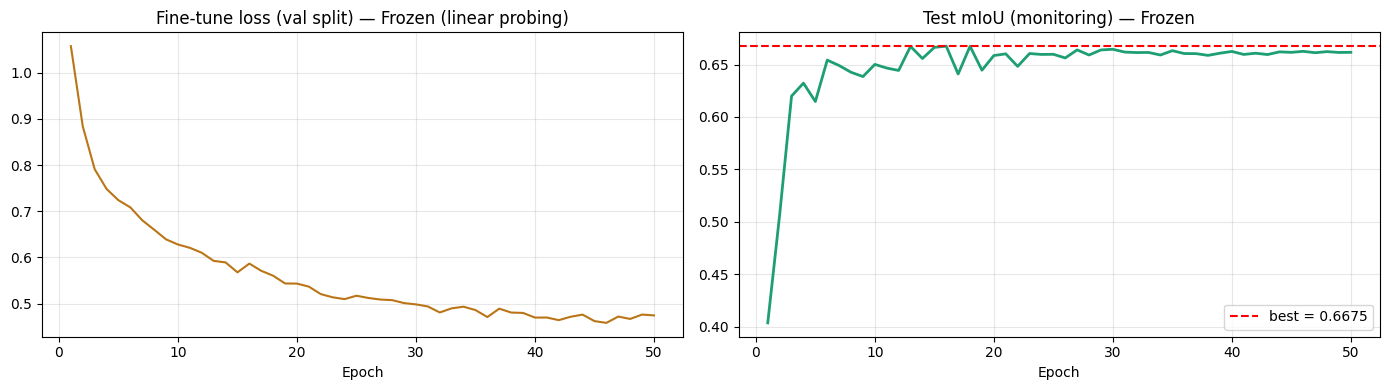

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(range(1, 51), train_losses_fz, color="#BA7517")
axes[0].set_title("Fine-tune loss (val split) — Frozen (linear probing)"); axes[0].set_xlabel("Epoch"); axes[0].grid(alpha=0.3)

axes[1].plot(range(1, 51), test_mious_fz, color="#1D9E75", linewidth=2)
axes[1].axhline(best_miou_fz, color="red", linestyle="--", label=f"best = {best_miou_fz:.4f}")
axes[1].set_title("Test mIoU (monitoring) — Frozen"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig("/kaggle/working/simclr_frozen_curves.png", dpi=150); plt.show()

Frozen final evaluation

=== SimCLR FROZEN (linear probing) — test metrics ===
Test mIoU:       0.6675
IoU background:  0.9908
IoU plaque:      0.3442
Mean Dice:       0.7537
Dice plaque:     0.5121
Pixel accuracy:  0.9909


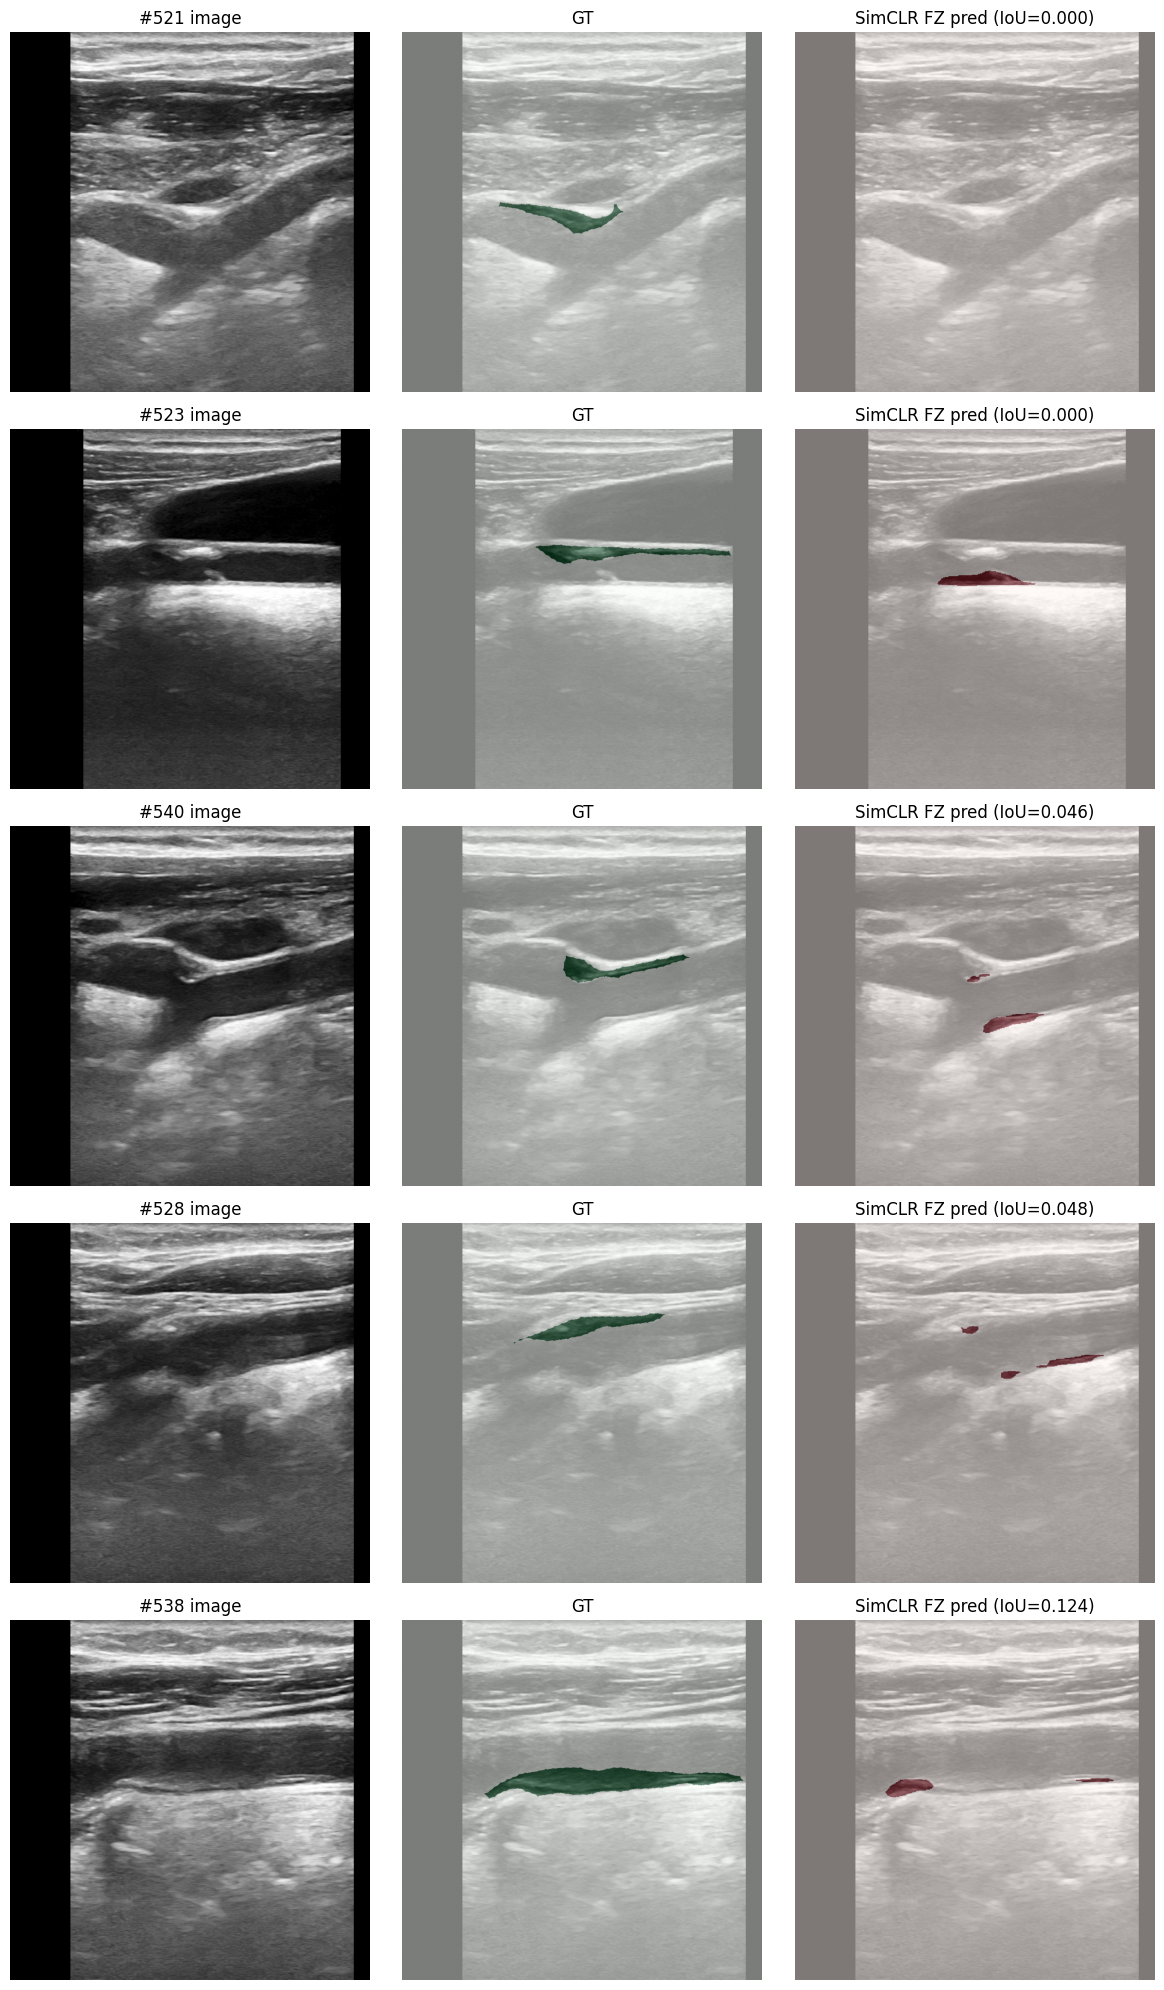

In [17]:
seg_model_fz.load_state_dict(torch.load("/kaggle/working/simclr_seg_fz_best.pt"))
final_overall_fz, final_per_image_fz = evaluate(seg_model_fz, test_loader)

print("=== SimCLR FROZEN (linear probing) — test metrics ===")
print(f"Test mIoU:       {final_overall_fz['mIoU']:.4f}")
print(f"IoU background:  {final_overall_fz['iou_per_class'][0]:.4f}")
print(f"IoU plaque:      {final_overall_fz['iou_per_class'][1]:.4f}")
print(f"Mean Dice:       {final_overall_fz['mean_dice']:.4f}")
print(f"Dice plaque:     {final_overall_fz['dice_per_class'][1]:.4f}")
print(f"Pixel accuracy:  {final_overall_fz['overall_pixel_acc']:.4f}")

# Per-image + worst-cases for frozen variant (so we can save whichever wins)
per_img_df_fz = pd.DataFrame([{
    "idx": r["idx"],
    "plaque_iou": r["plaque_iou"],
    "has_plaque": r["has_plaque"]
} for r in final_per_image_fz])

positive_fz = per_img_df_fz[per_img_df_fz["has_plaque"] == 1]
worst10_fz = positive_fz.nsmallest(10, "plaque_iou")

per_img_df_fz.to_csv("/kaggle/working/simclr_per_image_fz.csv", index=False)

worst5_idx = worst10_fz["idx"].tolist()[:5]
fig, axes = plt.subplots(5, 3, figsize=(12, 20))
for row, idx in enumerate(worst5_idx):
    rec = next(r for r in test_records if str(r["idx"]) == str(idx))
    img = cv2.imread(rec["img_path"], cv2.IMREAD_GRAYSCALE)
    gt = (cv2.imread(rec["mask_path"], cv2.IMREAD_GRAYSCALE) > MASK_THRESHOLD).astype(np.uint8)

    img_t = torch.from_numpy(cv2.cvtColor(cv2.resize(img, (IMG_SIZE, IMG_SIZE)), cv2.COLOR_GRAY2RGB))
    img_t = (img_t.permute(2,0,1).float()/255.0 - torch.tensor([0.485,0.456,0.406]).view(3,1,1)) / torch.tensor([0.229,0.224,0.225]).view(3,1,1)
    seg_model_fz.eval()
    with torch.no_grad():
        pred = seg_model_fz(img_t.unsqueeze(0).to(device)).argmax(1)[0].cpu().numpy()
    pred = cv2.resize(pred.astype(np.uint8), (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)

    axes[row,0].imshow(img, cmap="gray"); axes[row,0].set_title(f"#{idx} image"); axes[row,0].axis("off")
    axes[row,1].imshow(img, cmap="gray"); axes[row,1].imshow(gt, cmap="Greens", alpha=0.5); axes[row,1].set_title("GT"); axes[row,1].axis("off")
    axes[row,2].imshow(img, cmap="gray"); axes[row,2].imshow(pred, cmap="Reds", alpha=0.5); axes[row,2].set_title(f"SimCLR FZ pred (IoU={worst10_fz.iloc[row]['plaque_iou']:.3f})"); axes[row,2].axis("off")
plt.tight_layout(); plt.savefig("/kaggle/working/simclr_worst_cases_fz.png", dpi=100); plt.show()

Frozen vs Fine-tuned

Comparison + winner selection

 SimCLR — frozen vs fine-tuned encoder (test set)
Metric                     Frozen     Fine-tuned      Δ (FT-Fz)
------------------------------------------------------------
Test mIoU                  0.6675         0.6730        +0.0055
IoU background             0.9908         0.9923        +0.0015
IoU plaque                 0.3442         0.3537        +0.0095
Mean Dice                  0.7537         0.7593        +0.0056
Dice plaque                0.5121         0.5225        +0.0104
Pixel accuracy             0.9909         0.9923        +0.0015
------------------------------------------------------------


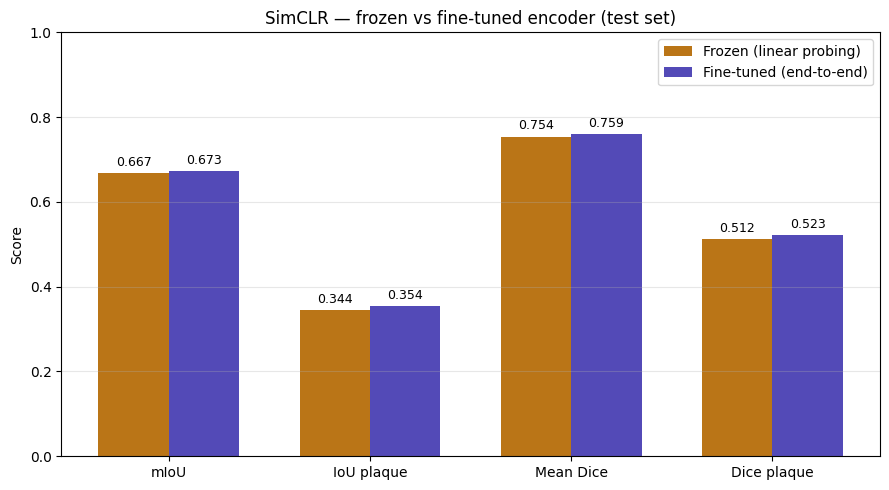


>>> Winner: FINE-TUNED  (mIoU gap FT − Fz = +0.0055)
>>> Decision: use fine-tuned strategy for BYOL, MAE, and DINOv2 downstream.


In [18]:
def gap(a, b):
    diff = a - b
    return f"{diff:+.4f}"

print("=" * 60)
print(" SimCLR — frozen vs fine-tuned encoder (test set)")
print("=" * 60)
print(f"{'Metric':<20} {'Frozen':>12} {'Fine-tuned':>14} {'Δ (FT-Fz)':>14}")
print("-" * 60)
for name, fz_val, ft_val in [
    ("Test mIoU",       final_overall_fz["mIoU"],               final_overall_ft["mIoU"]),
    ("IoU background",  final_overall_fz["iou_per_class"][0],   final_overall_ft["iou_per_class"][0]),
    ("IoU plaque",      final_overall_fz["iou_per_class"][1],   final_overall_ft["iou_per_class"][1]),
    ("Mean Dice",       final_overall_fz["mean_dice"],          final_overall_ft["mean_dice"]),
    ("Dice plaque",     final_overall_fz["dice_per_class"][1],  final_overall_ft["dice_per_class"][1]),
    ("Pixel accuracy",  final_overall_fz["overall_pixel_acc"],  final_overall_ft["overall_pixel_acc"]),
]:
    print(f"{name:<20} {fz_val:>12.4f} {ft_val:>14.4f} {gap(ft_val, fz_val):>14}")
print("-" * 60)

fig, ax = plt.subplots(figsize=(9, 5))
labels = ["mIoU", "IoU plaque", "Mean Dice", "Dice plaque"]
frozen_vals    = [final_overall_fz["mIoU"], final_overall_fz["iou_per_class"][1],
                  final_overall_fz["mean_dice"], final_overall_fz["dice_per_class"][1]]
finetuned_vals = [final_overall_ft["mIoU"], final_overall_ft["iou_per_class"][1],
                  final_overall_ft["mean_dice"], final_overall_ft["dice_per_class"][1]]

x = np.arange(len(labels))
w = 0.35
b1 = ax.bar(x - w/2, frozen_vals,    w, label="Frozen (linear probing)", color="#BA7517")
b2 = ax.bar(x + w/2, finetuned_vals, w, label="Fine-tuned (end-to-end)", color="#534AB7")
for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.01, f"{h:.3f}",
                ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylim(0, 1.0); ax.set_ylabel("Score")
ax.set_title("SimCLR — frozen vs fine-tuned encoder (test set)")
ax.legend(); ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig("/kaggle/working/simclr_frozen_vs_finetuned.png", dpi=150, bbox_inches="tight")
plt.show()


if final_overall_ft["mIoU"] >= final_overall_fz["mIoU"]:
    winner              = "fine-tuned"
    winner_overall      = final_overall_ft
    winner_per_image    = final_per_image_ft
    winner_state        = best_state_ft
    winner_best_epoch   = best_epoch_ft
    winner_config       = FT_CONFIG
    winner_train_losses = train_losses_ft
    winner_test_mious   = test_mious_ft
    winner_epoch_times  = epoch_times_ft
else:
    winner              = "frozen"
    winner_overall      = final_overall_fz
    winner_per_image    = final_per_image_fz
    winner_state        = best_state_fz
    winner_best_epoch   = best_epoch_fz
    winner_config       = FZ_CONFIG
    winner_train_losses = train_losses_fz
    winner_test_mious   = test_mious_fz
    winner_epoch_times  = epoch_times_fz

delta_miou = final_overall_ft["mIoU"] - final_overall_fz["mIoU"]
print(f"\n>>> Winner: {winner.upper()}  (mIoU gap FT − Fz = {delta_miou:+.4f})")
print(f">>> Decision: use {winner} strategy for BYOL, MAE, and DINOv2 downstream.")

Save only the winner's outputs

In [19]:
pretrain_epoch_times = epoch_times

Worst 10 by plaque IoU (fine-tuned):
    idx  plaque_iou  has_plaque
23  521    0.000000           1
25  523    0.000000           1
30  528    0.000000           1
40  538    0.069127           1
44  542    0.103524           1
45  543    0.206118           1
43  541    0.297611           1
35  533    0.297840           1
27  525    0.302256           1
26  524    0.326641           1


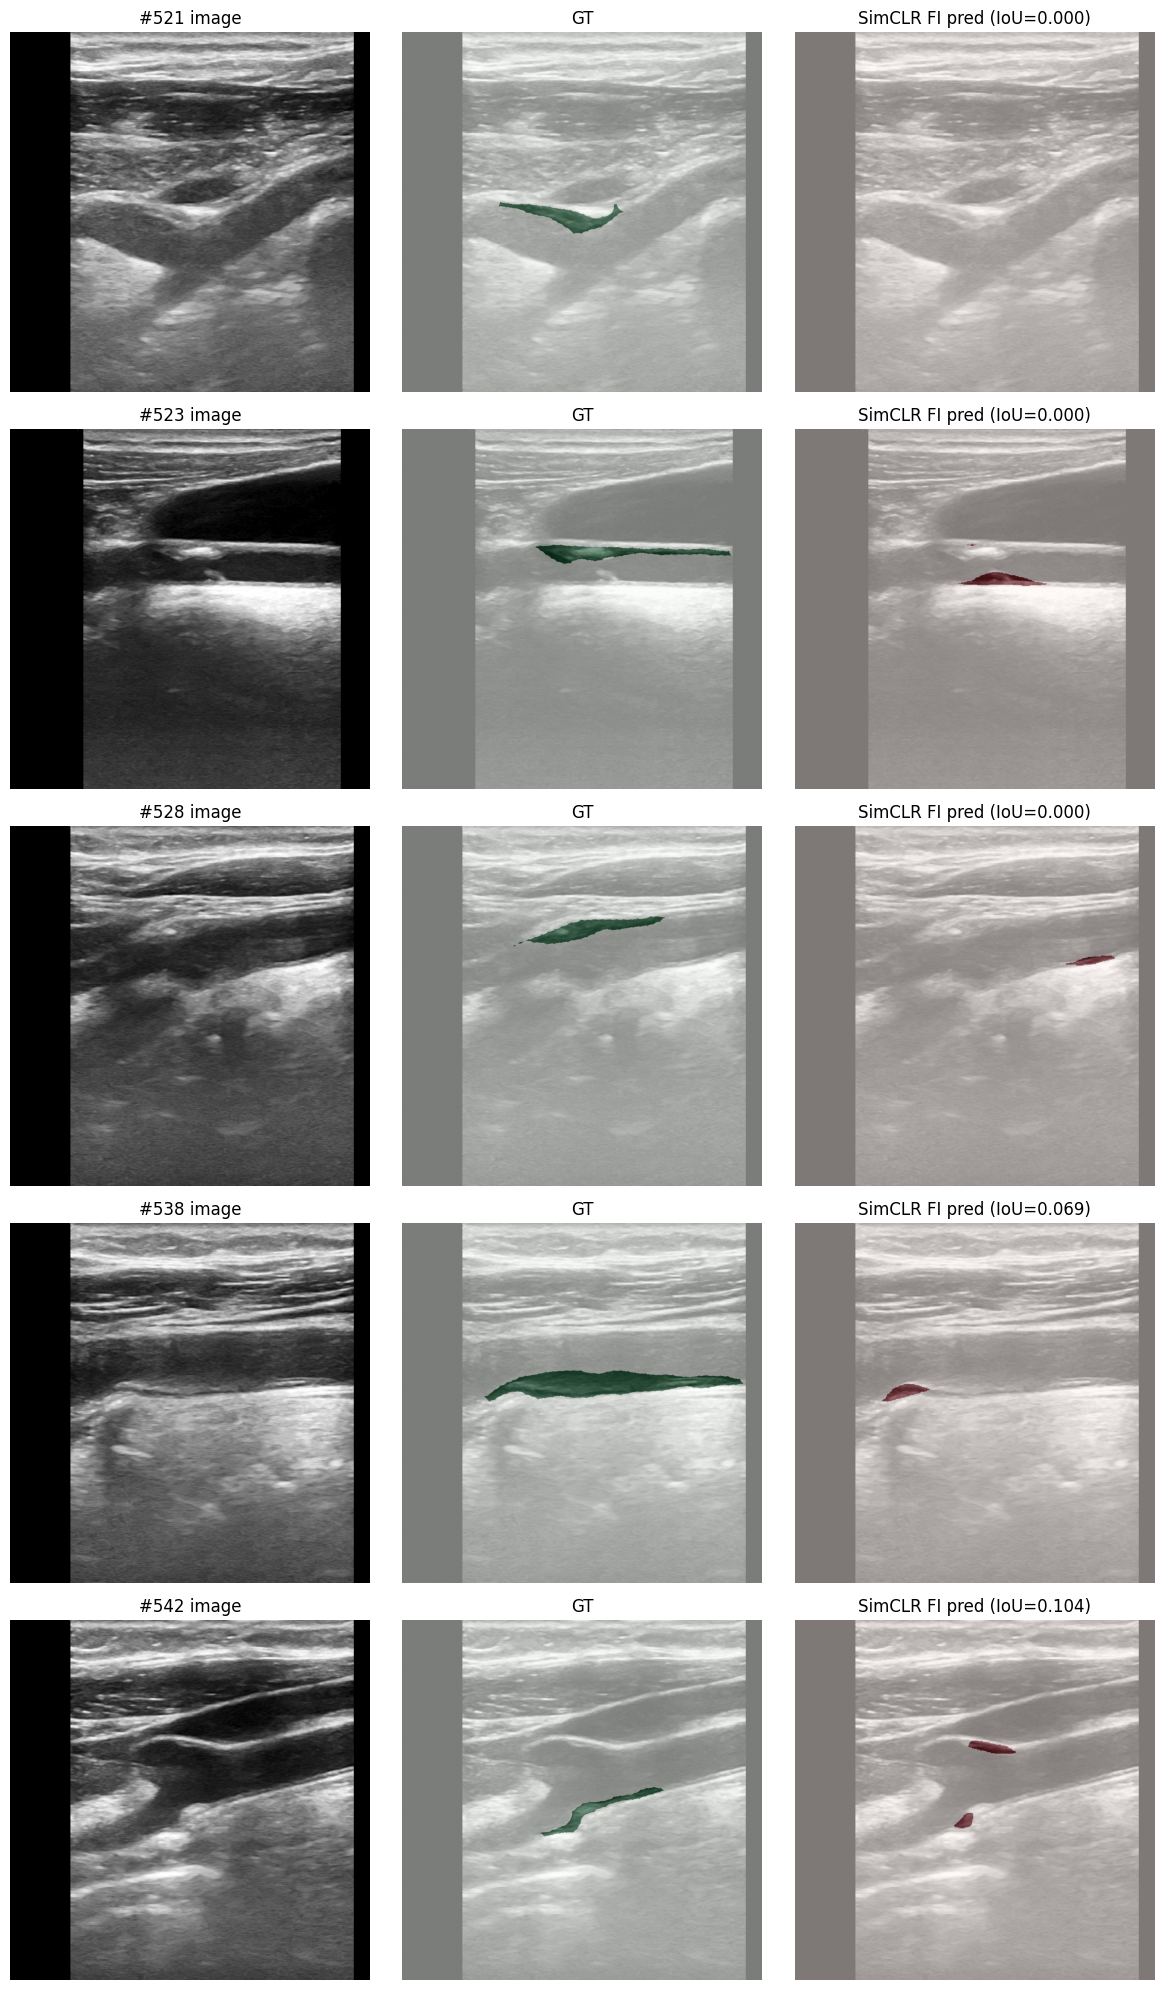

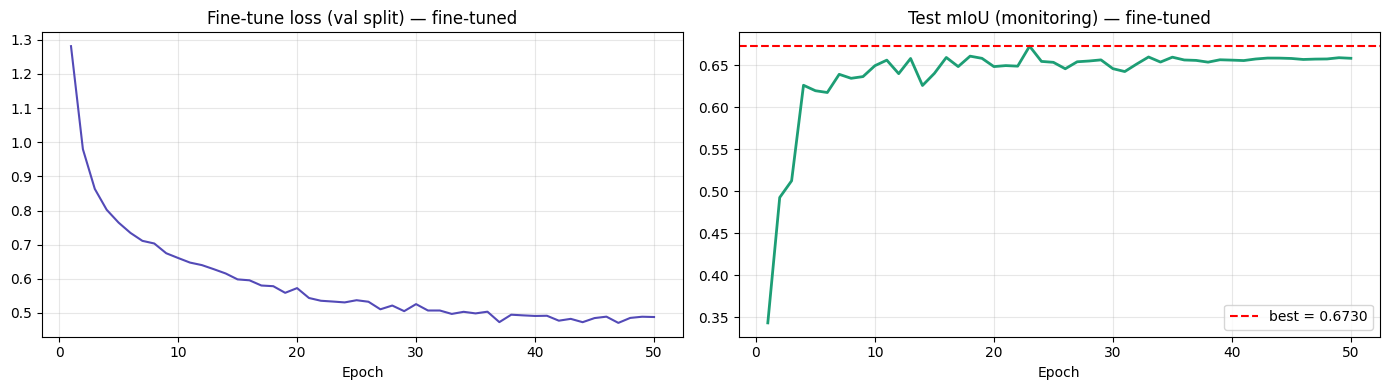


 Saved outputs for SimCLR (fine-tuned variant chosen)
  /kaggle/working/simclr_encoder.pt              (pretrained encoder)
  /kaggle/working/simclr_seg_best.pt             (winning downstream checkpoint)
  /kaggle/working/simclr_per_image.csv           (winner per-image metrics)
  /kaggle/working/simclr_worst_cases.png         (winner worst-5 failures)
  /kaggle/working/simclr_training_curves.png     (winner training curves)
  /kaggle/working/simclr_pretrain_loss.png       (pretraining loss)
  /kaggle/working/simclr_frozen_vs_finetuned.png (ablation bar chart)
  /kaggle/working/results_simclr.json            (winner + both variants + ablation)

>>> Winner:      FINE-TUNED  (test mIoU 0.6730)
>>> Best epoch:  23


In [20]:
import shutil, os

torch.save(winner_state, "/kaggle/working/simclr_seg_best.pt")

winner_df = pd.DataFrame([{
    "idx": r["idx"],
    "plaque_iou": r["plaque_iou"],
    "has_plaque": r["has_plaque"]
} for r in winner_per_image])
winner_df.to_csv("/kaggle/working/simclr_per_image.csv", index=False)

winner_seg_model = SegModel("/kaggle/working/simclr_encoder.pt", num_classes=2).to(device)
winner_seg_model.load_state_dict(winner_state)
winner_seg_model.eval()

winner_positive = winner_df[winner_df["has_plaque"] == 1]
winner_worst10  = winner_positive.nsmallest(10, "plaque_iou")

print(f"Worst 10 by plaque IoU ({winner}):")
print(winner_worst10)

worst5_idx = winner_worst10["idx"].tolist()[:5]
fig, axes = plt.subplots(5, 3, figsize=(12, 20))
for row, idx in enumerate(worst5_idx):
    rec = next(r for r in test_records if str(r["idx"]) == str(idx))
    img = cv2.imread(rec["img_path"], cv2.IMREAD_GRAYSCALE)
    gt = (cv2.imread(rec["mask_path"], cv2.IMREAD_GRAYSCALE) > MASK_THRESHOLD).astype(np.uint8)

    img_t = torch.from_numpy(cv2.cvtColor(cv2.resize(img, (IMG_SIZE, IMG_SIZE)), cv2.COLOR_GRAY2RGB))
    img_t = (img_t.permute(2,0,1).float()/255.0 - torch.tensor([0.485,0.456,0.406]).view(3,1,1)) / torch.tensor([0.229,0.224,0.225]).view(3,1,1)
    with torch.no_grad():
        pred = winner_seg_model(img_t.unsqueeze(0).to(device)).argmax(1)[0].cpu().numpy()
    pred = cv2.resize(pred.astype(np.uint8), (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)

    axes[row,0].imshow(img, cmap="gray"); axes[row,0].set_title(f"#{idx} image"); axes[row,0].axis("off")
    axes[row,1].imshow(img, cmap="gray"); axes[row,1].imshow(gt, cmap="Greens", alpha=0.5); axes[row,1].set_title("GT"); axes[row,1].axis("off")
    axes[row,2].imshow(img, cmap="gray"); axes[row,2].imshow(pred, cmap="Reds", alpha=0.5); axes[row,2].set_title(f"SimCLR {winner[:2].upper()} pred (IoU={winner_worst10.iloc[row]['plaque_iou']:.3f})"); axes[row,2].axis("off")
plt.tight_layout()
plt.savefig("/kaggle/working/simclr_worst_cases.png", dpi=100)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(range(1, 51), winner_train_losses, color="#534AB7")
axes[0].set_title(f"Fine-tune loss (val split) — {winner}")
axes[0].set_xlabel("Epoch"); axes[0].grid(alpha=0.3)

axes[1].plot(range(1, 51), winner_test_mious, color="#1D9E75", linewidth=2)
axes[1].axhline(winner_overall["mIoU"], color="red", linestyle="--",
                label=f"best = {winner_overall['mIoU']:.4f}")
axes[1].set_title(f"Test mIoU (monitoring) — {winner}")
axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/simclr_training_curves.png", dpi=150)
plt.show()

results = {
    "model": "SimCLR (ResNet-50) + YOLOv26-style decoder",
    "ssl_method": "SimCLR",
    "backbone": "ResNet-50",
    "pretrain_source": "ImageNet-pretrained + SSL fine-tuned on train split",
    "pretrain_epochs": 50,
    "pretrain_temperature": 0.5,
    "pretrain_mean_epoch_sec": float(np.mean(pretrain_epoch_times)),
    "pretrain_total_min": float(sum(pretrain_epoch_times) / 60),
    "finetune_epochs": 50,
    "labeled_images_used": len(val_records),

    "frozen_or_finetuned": winner,
    "best_epoch": winner_best_epoch,
    "config_used": winner_config,
    "test_metrics": winner_overall,
    "per_image_results": [
        {"idx": r["idx"], "plaque_iou": r["plaque_iou"], "has_plaque": r["has_plaque"]}
        for r in winner_per_image
    ],

    "ablation_frozen_vs_finetuned": {
        "fine_tuned": {
            "best_epoch": best_epoch_ft,
            "test_mIoU": final_overall_ft["mIoU"],
            "iou_background": final_overall_ft["iou_per_class"][0],
            "iou_plaque": final_overall_ft["iou_per_class"][1],
            "mean_dice": final_overall_ft["mean_dice"],
            "dice_plaque": final_overall_ft["dice_per_class"][1],
            "overall_pixel_acc": final_overall_ft["overall_pixel_acc"],
        },
        "frozen": {
            "best_epoch": best_epoch_fz,
            "test_mIoU": final_overall_fz["mIoU"],
            "iou_background": final_overall_fz["iou_per_class"][0],
            "iou_plaque": final_overall_fz["iou_per_class"][1],
            "mean_dice": final_overall_fz["mean_dice"],
            "dice_plaque": final_overall_fz["dice_per_class"][1],
            "overall_pixel_acc": final_overall_fz["overall_pixel_acc"],
        },
        "mIoU_gap_ft_minus_fz": delta_miou,
        "winner": winner,
        "decision_for_other_methods": (
            f"Use {winner} strategy for BYOL, MAE, and DINOv2 based on SimCLR ablation."
        ),
    },
}

with open("/kaggle/working/results_simclr.json", "w") as f:
    json.dump(results, f, indent=2)

for f in [
    "/kaggle/working/simclr_seg_ft_best.pt",
    "/kaggle/working/simclr_seg_fz_best.pt",
    "/kaggle/working/simclr_finetune_curves.png", 
    "/kaggle/working/simclr_frozen_curves.png",    
]:
    if os.path.exists(f):
        os.remove(f)

print(f"\n{'='*60}")
print(f" Saved outputs for SimCLR ({winner} variant chosen)")
print(f"{'='*60}")
print(f"  /kaggle/working/simclr_encoder.pt              (pretrained encoder)")
print(f"  /kaggle/working/simclr_seg_best.pt             (winning downstream checkpoint)")
print(f"  /kaggle/working/simclr_per_image.csv           (winner per-image metrics)")
print(f"  /kaggle/working/simclr_worst_cases.png         (winner worst-5 failures)")
print(f"  /kaggle/working/simclr_training_curves.png     (winner training curves)")
print(f"  /kaggle/working/simclr_pretrain_loss.png       (pretraining loss)")
print(f"  /kaggle/working/simclr_frozen_vs_finetuned.png (ablation bar chart)")
print(f"  /kaggle/working/results_simclr.json            (winner + both variants + ablation)")
print(f"\n>>> Winner:      {winner.upper()}  (test mIoU {winner_overall['mIoU']:.4f})")
print(f">>> Best epoch:  {winner_best_epoch}")